In [147]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

import cvxpy as cp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel
from Components.Controllers import LTI_LQRc_RHG

In [148]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [149]:
parameter_file = "Components/Setup/dense_aquifer.json"

In [150]:
# Initialize Model
model = SquareCoarseModel(parameter_file)

# Test Stability

In [151]:
A_dense = model.A.toarray()
A_coarse = SquareCoarseModel("Components/Setup/aquifer_parameters.json").A.toarray()

In [152]:
A_dense

array([[-0.02,  0.51,  0.  , ...,  0.  ,  0.  ,  0.  ],
       [ 0.51, -0.53,  0.51, ...,  0.  ,  0.  ,  0.  ],
       [ 0.  ,  0.51, -0.53, ...,  0.  ,  0.  ,  0.  ],
       ...,
       [ 0.  ,  0.  ,  0.  , ..., -0.53,  0.51,  0.  ],
       [ 0.  ,  0.  ,  0.  , ...,  0.51, -0.53,  0.51],
       [ 0.  ,  0.  ,  0.  , ...,  0.  ,  0.51, -0.02]], shape=(100, 100))

In [153]:
np.unique(A_dense), np.unique(A_coarse)

(array([-1.04, -0.53, -0.02,  0.  ,  0.51]),
 array([0.    , 0.1275, 0.49  , 0.6175, 0.745 ]))

In [154]:
0.1275 * 4

0.51

In [155]:
np.abs(np.linalg.eigvals(A_dense)).max(), np.abs(np.linalg.eigvals(A_coarse)).max()

(np.float64(2.9801552932421105), np.float64(1.0000000000000002))

In [156]:
A_dense_dt_2 = A_dense/2 + (1/2)*np.eye(A_dense.shape[0])
A_dense_dt_3 = A_dense/3 + (2/3)*np.eye(A_dense.shape[0])
A_dense_dt_4 = A_dense/4 + (3/4)*np.eye(A_dense.shape[0])
np.abs(np.linalg.eigvals(A_dense)).max(), np.abs(np.linalg.eigvals(A_dense_dt_2@A_dense_dt_2)).max(), np.abs(np.linalg.eigvals(np.linalg.matrix_power(A_dense_dt_3, 3))).max(), np.abs(np.linalg.eigvals(np.linalg.matrix_power(A_dense_dt_4, 4))).max()

(np.float64(2.9801552932421105),
 np.float64(1.0000000000000016),
 np.float64(0.9999999999999979),
 np.float64(0.9999999999999973))

In [157]:
np.unique(A_dense_dt_2), np.unique(A_dense_dt_3)

(array([-0.02 ,  0.   ,  0.235,  0.255,  0.49 ]),
 array([0.  , 0.17, 0.32, 0.49, 0.66]))

In [158]:
A_dense_dt_2, A_dense_dt_3

(array([[0.49 , 0.255, 0.   , ..., 0.   , 0.   , 0.   ],
        [0.255, 0.235, 0.255, ..., 0.   , 0.   , 0.   ],
        [0.   , 0.255, 0.235, ..., 0.   , 0.   , 0.   ],
        ...,
        [0.   , 0.   , 0.   , ..., 0.235, 0.255, 0.   ],
        [0.   , 0.   , 0.   , ..., 0.255, 0.235, 0.255],
        [0.   , 0.   , 0.   , ..., 0.   , 0.255, 0.49 ]], shape=(100, 100)),
 array([[0.66, 0.17, 0.  , ..., 0.  , 0.  , 0.  ],
        [0.17, 0.49, 0.17, ..., 0.  , 0.  , 0.  ],
        [0.  , 0.17, 0.49, ..., 0.  , 0.  , 0.  ],
        ...,
        [0.  , 0.  , 0.  , ..., 0.49, 0.17, 0.  ],
        [0.  , 0.  , 0.  , ..., 0.17, 0.49, 0.17],
        [0.  , 0.  , 0.  , ..., 0.  , 0.17, 0.66]], shape=(100, 100)))

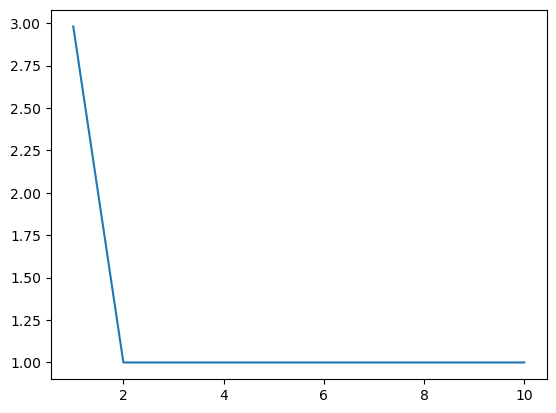

In [159]:
pow = np.linspace(1,10,10, dtype=int)
e = np.array([np.abs(np.linalg.eigvals(np.linalg.matrix_power(A_dense/k + (1-1/k)*np.eye(A_dense.shape[0]), k))).max() for k in pow])
plt.plot(pow, e)

In [160]:
e<=1+1e-10

array([False,  True,  True,  True,  True,  True,  True,  True,  True,  True])

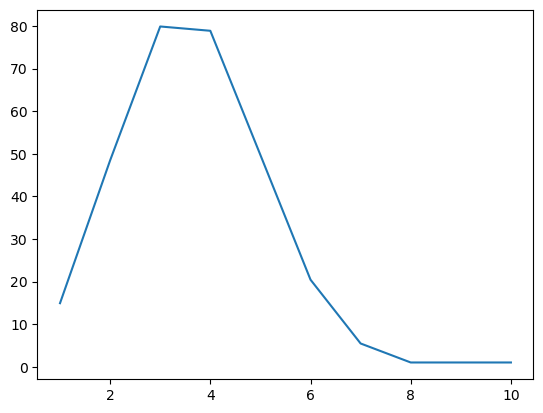

In [161]:
A_test = A_dense*4 - 3*np.eye(A_dense.shape[0])
pow = np.linspace(1,10,10, dtype=int)
e = np.array([np.abs(np.linalg.eigvals(np.linalg.matrix_power(A_test/k + (1-1/k)*np.eye(A_test.shape[0]), k))).max() for k in pow])
plt.plot(pow, e)

In [162]:
e<=1+1e-10

array([False, False, False, False, False, False, False,  True,  True,  True])

In [163]:
min_factor = []
pow = np.linspace(1,50,50, dtype=int)
for p in range(1,11):
    A_test = A_coarse*(p**2) + (1-p**2)*np.eye(A_coarse.shape[0])
    e = np.array([np.abs(np.linalg.eigvals(np.linalg.matrix_power(A_test/k + (1-1/k)*np.eye(A_test.shape[0]), k))).max() for k in pow])
    min_factor.append(np.min(pow[e<=1+1e-10]))
    
np.vstack([
    np.array(min_factor), \
    np.array([(p**2/2) for p in range(1,11)])])

array([[ 1. ,  2. ,  5. ,  8. , 12. , 17. , 23. , 30. , 38. , 47. ],
       [ 0.5,  2. ,  4.5,  8. , 12.5, 18. , 24.5, 32. , 40.5, 50. ]])

In [233]:
min_factor = []
pow = np.linspace(1,50,50, dtype=int)
for p in range(1,11):
    A_test = A_coarse*(p**2) + (1-p**2)*np.eye(A_coarse.shape[0])
    e = np.array([np.abs(np.linalg.eigvals(A_test/k + (1-1/k)*np.eye(A_test.shape[0]))).max() for k in pow])
    min_factor.append(np.min(pow[e<=1+1e-10]))

np.array(min_factor)

array([ 1,  2,  5,  8, 12, 17, 23, 30, 38, 47])

Proof of a relation?

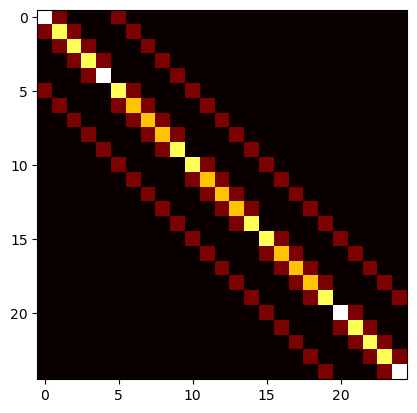

In [164]:
plt.imshow(A_coarse, cmap='hot', interpolation='nearest')

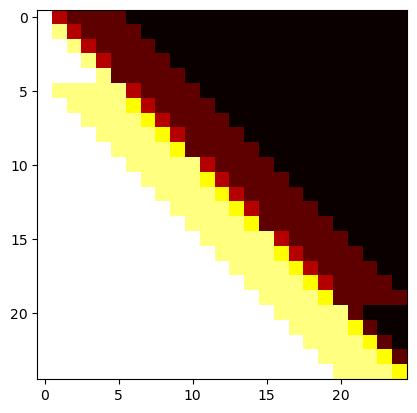

In [165]:
A_m = A_coarse.copy()
for k in range(24):
    A_m[:,k] = A_m[:,k] + np.sum(A_m[:,k+1:], axis=1)
plt.imshow(A_m, cmap='hot', interpolation='nearest')

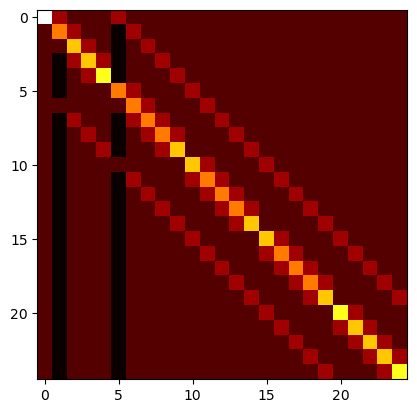

In [166]:
A_m = A_coarse.copy()
A_m[:,0] = A_m[:,0] + np.sum(A_m[:,0+1:], axis=1)
for k in range(1,25):
    A_m[k,:] = A_m[k,:] - A_m[0,:]
plt.imshow(A_m, cmap='hot', interpolation='nearest')

In [182]:
A_m[0,1]*3

np.float64(0.3825)

In [181]:
1-np.sum(A_m[1:,1:], axis=1)

array([0.3825, 0.255 , 0.255 , 0.255 , 0.3825, 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 , 0.255 ])

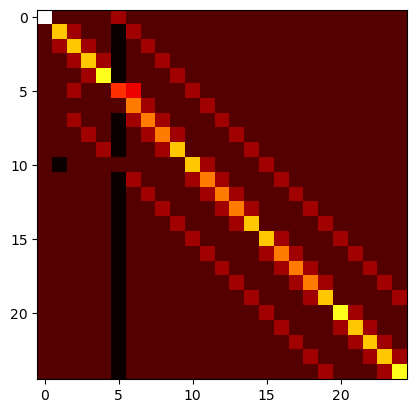

In [ ]:
A_m[:,1] = A_m[:,1] - A_m[:,5]
A_m[5,:] += A_m[1,:]
plt.imshow(A_m, cmap='hot', interpolation='nearest')

In [199]:
((1-np.linalg.eigvals(A_coarse))/A_coarse[0,1]).round(3)

array([ 7.236, -0.   ,  0.764,  5.236,  6.236,  6.236,  0.382,  0.382,  2.764,  5.   ,  5.   ,  1.382,  1.382,  1.764,  1.764,  3.   ,  2.618,  2.618,  3.   ,  3.618,  3.618,  4.   ,  4.   ,  4.   ,  4.   ])

In [196]:
import sympy

l, mu = sympy.symbols(['l', 'mu'])
A_symb = (1)*sympy.eye(9) - sympy.Matrix([[-2*mu, mu, 0, mu, 0, 0, 0, 0, 0],
                                           [mu, -3*mu, mu, 0, mu, 0, 0, 0, 0],
                                           [0, mu, -2*mu, 0, 0, mu, 0, 0, 0],
                                           [mu, 0, 0, -3*mu, mu, 0, mu, 0, 0],
                                           [0, mu, 0, mu, -4*mu, mu, 0, mu, 0],
                                           [0, 0, mu, 0, mu, -3*mu, 0, 0, mu],
                                           [0, 0, 0, mu, 0, 0, -2*mu, mu, 0],
                                           [0, 0, 0, 0, mu, 0, mu, -3*mu, mu],
                                           [0, 0, 0, 0, 0, mu, 0, mu, -2*mu]])

In [197]:
A_symb.eigenvals()

{6*mu + 1: 1, 2*mu + 1: 1, 1: 1, 4*mu + 1: 2, 3*mu + 1: 2, mu + 1: 2}

In [210]:
import json
with open("Components/Setup/aquifer_parameters.json", 'r') as file:
    params = json.load(file)
adj, _, _, _ = SquareCoarseModel("Components/Setup/aquifer_parameters.json")._get_grid_parameter_matrices(params)

In [230]:
A_symb = sympy.Matrix(mu * adj.toarray().astype(int) - mu*np.diag(np.sum(adj.toarray(), axis=0)).astype(int))+sympy.eye(25)
A_symb.eigenvals()

{1: 1,
 1 - 3*mu: 2,
 1 - 5*mu: 2,
 1 - 4*mu: 4,
 -3*mu - sqrt(5)*mu + 1: 1,
 -3*mu + sqrt(5)*mu + 1: 1,
 -5*mu - sqrt(5)*mu + 1: 1,
 -5*mu + sqrt(5)*mu + 1: 1,
 -3*mu/2 - sqrt(5)*mu/2 + 1: 2,
 -3*mu/2 + sqrt(5)*mu/2 + 1: 2,
 -5*mu/2 - sqrt(5)*mu/2 + 1: 2,
 -5*mu/2 + sqrt(5)*mu/2 + 1: 2,
 -4*mu - sqrt(5)*mu + 1: 2,
 -4*mu + sqrt(5)*mu + 1: 2}